In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


First five records:
   Age  Gender  Income  Purchases  Order_Value  Website_Visits Membership  \
0   56    Male   49241          2          978              30       Gold   
1   46  Female  116214         28         9977              25     Silver   
2   32  Female   64569         23         1692              45    Regular   
3   60  Female   31745         19          860              28    Regular   
4   25    Male   46029         19         1548               1    Regular   

      Category  Annual_Spending Spending_Category  
0  Electronics            23472               Low  
1  Electronics          3352272              High  
2  Electronics           466992            Medium  
3         Home           196080               Low  
4      Fashion           352944               Low  

Dataset shape: (1000, 10)

Missing values:
Age                  0
Gender               0
Income               0
Purchases            0
Order_Value          0
Website_Visits       0
Membership           0


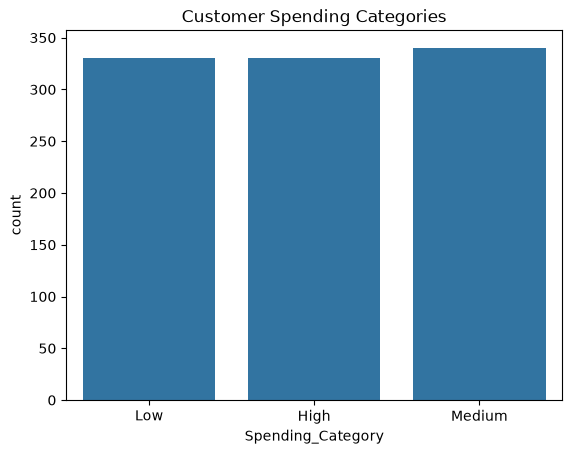

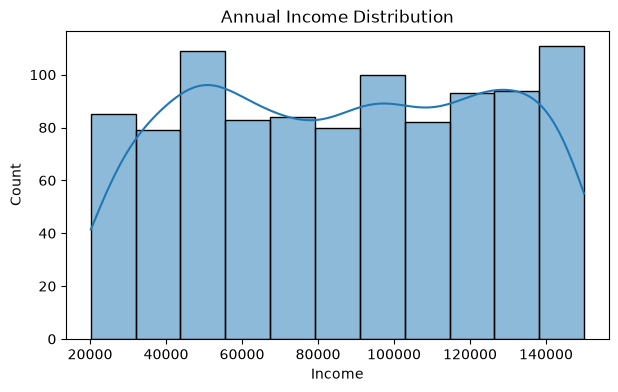

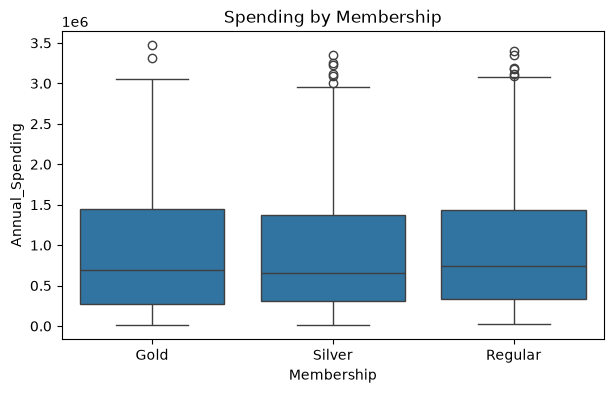

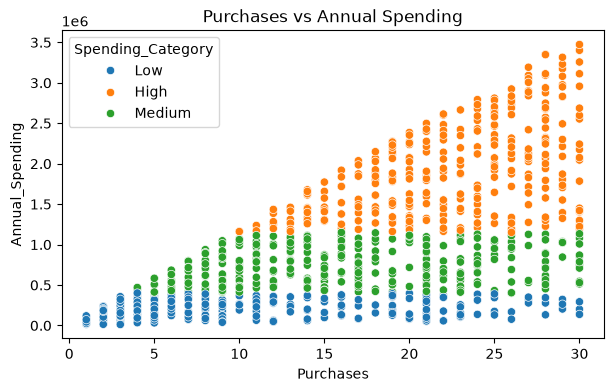

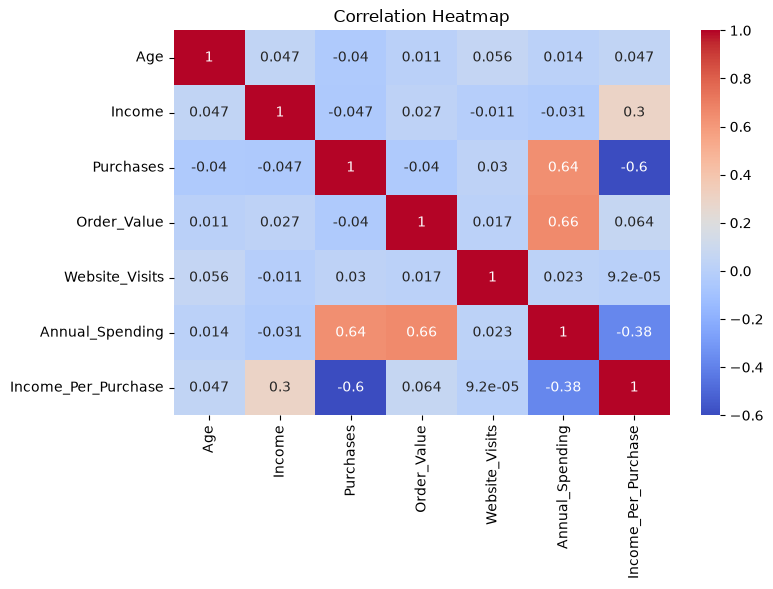


Model comparison:
                     Accuracy  Precision  Recall  F1 Score
Logistic Regression     0.625      0.625   0.625     0.618
Decision Tree           0.570      0.560   0.570     0.562


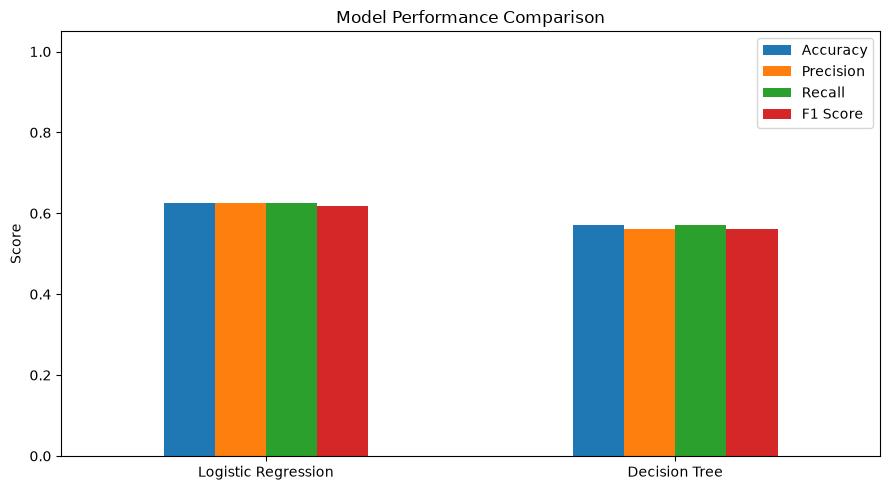


Best model: Logistic Regression

Classification report:
              precision    recall  f1-score   support

        High       0.63      0.82      0.71        66
         Low       0.73      0.62      0.67        66
      Medium       0.52      0.44      0.48        68

    accuracy                           0.62       200
   macro avg       0.63      0.63      0.62       200
weighted avg       0.62      0.62      0.62       200



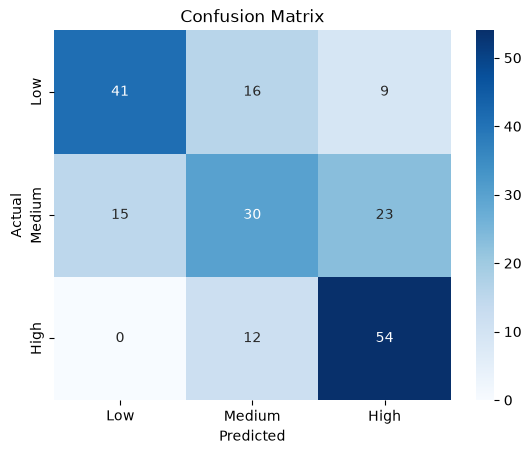

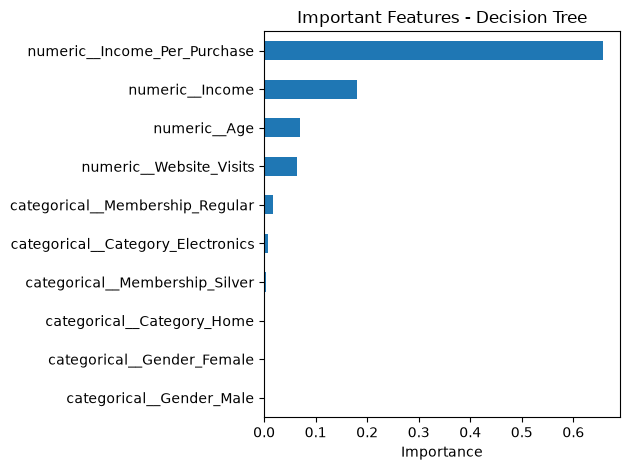


Predicted spending category: Medium

Average spending by membership:
Membership
Gold       930700.17
Regular    977855.36
Silver     950626.90
Name: Annual_Spending, dtype: float64

Average income by spending category:
Spending_Category
High      86625.03
Low       88526.72
Medium    85851.27
Name: Income, dtype: float64

Project completed.


In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

# Creating a sample customer dataset
np.random.seed(42)

n = 1000

df = pd.DataFrame({
    "Age": np.random.randint(18, 65, n),
    "Gender": np.random.choice(["Male", "Female"], n),
    "Income": np.random.randint(20000, 150000, n),
    "Purchases": np.random.randint(1, 31, n),
    "Order_Value": np.random.randint(200, 10000, n),
    "Website_Visits": np.random.randint(1, 50, n),
    "Membership": np.random.choice(
        ["Regular", "Silver", "Gold"], n
    ),
    "Category": np.random.choice(
        ["Electronics", "Fashion", "Grocery", "Home"], n
    )
})

# Calculating estimated yearly spending
df["Annual_Spending"] = (
    df["Purchases"] * df["Order_Value"] * 12
)

# Dividing customers into three spending groups
low = df["Annual_Spending"].quantile(0.33)
high = df["Annual_Spending"].quantile(0.67)

df["Spending_Category"] = np.where(
    df["Annual_Spending"] <= low, "Low",
    np.where(df["Annual_Spending"] <= high, "Medium", "High")
)

print("First five records:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

# Removing duplicate records
df.drop_duplicates(inplace=True)

# Checking spending categories
print("\nSpending category counts:")
print(df["Spending_Category"].value_counts())

# Creating an additional feature
df["Income_Per_Purchase"] = (
    df["Income"] / df["Purchases"]
)

# Visualisation 1: Spending groups
sns.countplot(data=df, x="Spending_Category")
plt.title("Customer Spending Categories")
plt.show()

# Visualisation 2: Income distribution
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="Income", kde=True)
plt.title("Annual Income Distribution")
plt.show()

# Visualisation 3: Spending by membership
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="Membership", y="Annual_Spending")
plt.title("Spending by Membership")
plt.show()

# Visualisation 4: Purchases and spending
plt.figure(figsize=(7, 4))
sns.scatterplot(
    data=df,
    x="Purchases",
    y="Annual_Spending",
    hue="Spending_Category"
)
plt.title("Purchases vs Annual Spending")
plt.show()

# Visualisation 5: Correlation between numerical columns
plt.figure(figsize=(8, 5))
sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm"
)
plt.title("Correlation Heatmap")
plt.show()

# Preparing data for machine learning
X = df.drop(columns=[
    "Annual_Spending",
    "Spending_Category",
    "Purchases",
    "Order_Value"
])

y = df["Spending_Category"]

num_cols = X.select_dtypes(include="number").columns
cat_cols = X.select_dtypes(exclude="number").columns

num_process = Pipeline([
    ("fill", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])

cat_process = Pipeline([
    ("fill", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore"))
])

process = ColumnTransformer([
    ("numeric", num_process, num_cols),
    ("categorical", cat_process, cat_cols)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Training two models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=6, random_state=42
    )
}

scores = {}
trained_models = {}

for name, model in models.items():
    clf = Pipeline([
        ("preprocessing", process),
        ("model", model)
    ])

    clf.fit(X_train, y_train)
    pred = clf.predict(X_test)

    trained_models[name] = clf

    scores[name] = {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, average="weighted", zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, pred, average="weighted", zero_division=0
        )
    }

# Comparing model results
results = pd.DataFrame(scores).T

print("\nModel comparison:")
print(results.round(3))

results.plot(kind="bar", figsize=(9, 5))
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Selecting the model with the highest F1 score
best_name = results["F1 Score"].idxmax()
best_model = trained_models[best_name]

print("\nBest model:", best_name)

# Confusion matrix and classification report
pred = best_model.predict(X_test)

print("\nClassification report:")
print(classification_report(y_test, pred, zero_division=0))

cm = confusion_matrix(
    y_test, pred,
    labels=["Low", "Medium", "High"]
)

sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Low", "Medium", "High"],
    yticklabels=["Low", "Medium", "High"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# Feature importance for the decision tree model
tree_model = trained_models["Decision Tree"].named_steps["model"]

if hasattr(tree_model, "feature_importances_"):
    feature_names = trained_models[
        "Decision Tree"
    ].named_steps["preprocessing"].get_feature_names_out()

    importance = pd.Series(
        tree_model.feature_importances_,
        index=feature_names
    ).sort_values(ascending=False).head(10)

    importance.sort_values().plot(kind="barh")
    plt.title("Important Features - Decision Tree")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()

# Predicting spending for a new customer
new_customer = pd.DataFrame([{
    "Age": 30,
    "Gender": "Female",
    "Income": 75000,
    "Website_Visits": 20,
    "Membership": "Gold",
    "Category": "Electronics",
    "Income_Per_Purchase": 75000 / 15
}])

prediction = best_model.predict(new_customer)

print("\nPredicted spending category:", prediction[0])

# Basic business insights
print("\nAverage spending by membership:")
print(df.groupby("Membership")["Annual_Spending"].mean().round(2))

print("\nAverage income by spending category:")
print(df.groupby("Spending_Category")["Income"].mean().round(2))

print("\nProject completed.")
